In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


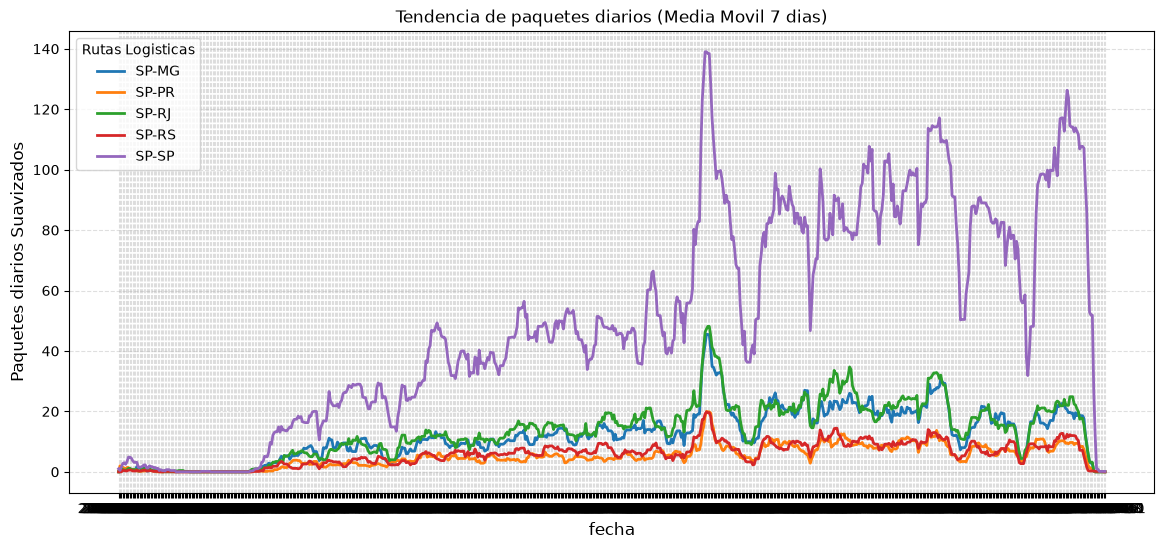

La ruta piloto seleccionda es: SP-SP


In [2]:
df = pd.read_csv('../data/dataset_rutas_limpios.csv')
df['media_paquetes_7d'] = (
    df.groupby('ruta')['total_paquetes_diarios'].transform(lambda x: x.rolling(window=7, min_periods=1).mean())
)
plt.figure(figsize=(14,6))
sns.lineplot(
    data=df,
    x='fecha',
    y='media_paquetes_7d',
    hue='ruta',
    linewidth=2
)
plt.title("Tendencia de paquetes diarios (Media Movil 7 dias)")
plt.xlabel('fecha',fontsize=12)
plt.ylabel('Paquetes diarios Suavizados', fontsize=12)
plt.legend(title='Rutas Logisticas')
plt.grid(True, linestyle='--',alpha=0.4)
plt.show()
ruta_piloto = df.groupby('ruta')['total_paquetes_diarios'].sum().idxmax()
print(f"La ruta piloto seleccionda es: {ruta_piloto}")

In [3]:
#Filtramos solo ruta piloto, para poder posteriormente entrenar el modelo
df_piloto = df[df['ruta'] == ruta_piloto].copy()
df_piloto = df_piloto.sort_values('fecha').reset_index(drop=True)
df_piloto['fecha'] = pd.to_datetime(df_piloto['fecha'])

dias_semana = {
    0:'Lunes',
    1:'Martes',
    2:'Miércoles',
    3:'Jueves',
    4:'Viernes',
    5:'Sábado',
    6:'Domingo'
}
df_piloto['num_dia'] = df_piloto['fecha'].dt.dayofweek
df_piloto['dia_semana'] = df_piloto['num_dia'].map(dias_semana)


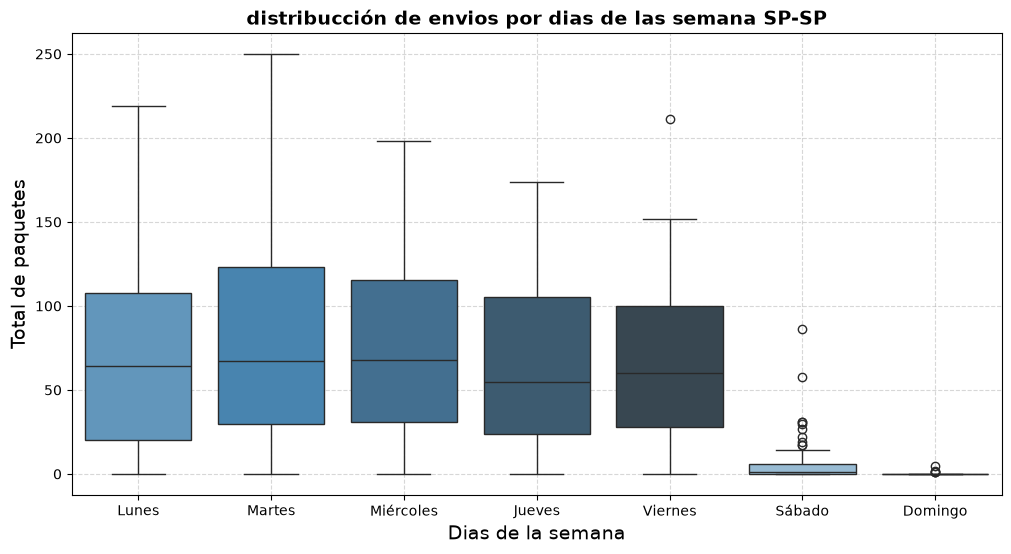

In [4]:
plt.figure(figsize=(12,6))

orden_dias=['Lunes','Martes','Miércoles','Jueves','Viernes','Sábado','Domingo']

sns.boxplot(
    data=df_piloto,
    x='dia_semana',
    y='total_paquetes_diarios',
    hue='dia_semana',
    order= orden_dias,
    palette='Blues_d',
    legend=False
)
plt.title(f'distribucción de envios por dias de las semana {ruta_piloto}', fontsize=14, fontweight='bold')
plt.xlabel('Dias de la semana', fontsize=14)
plt.ylabel('Total de paquetes',fontsize=14)
plt.grid(True,linestyle='--', alpha=0.5)
plt.show()

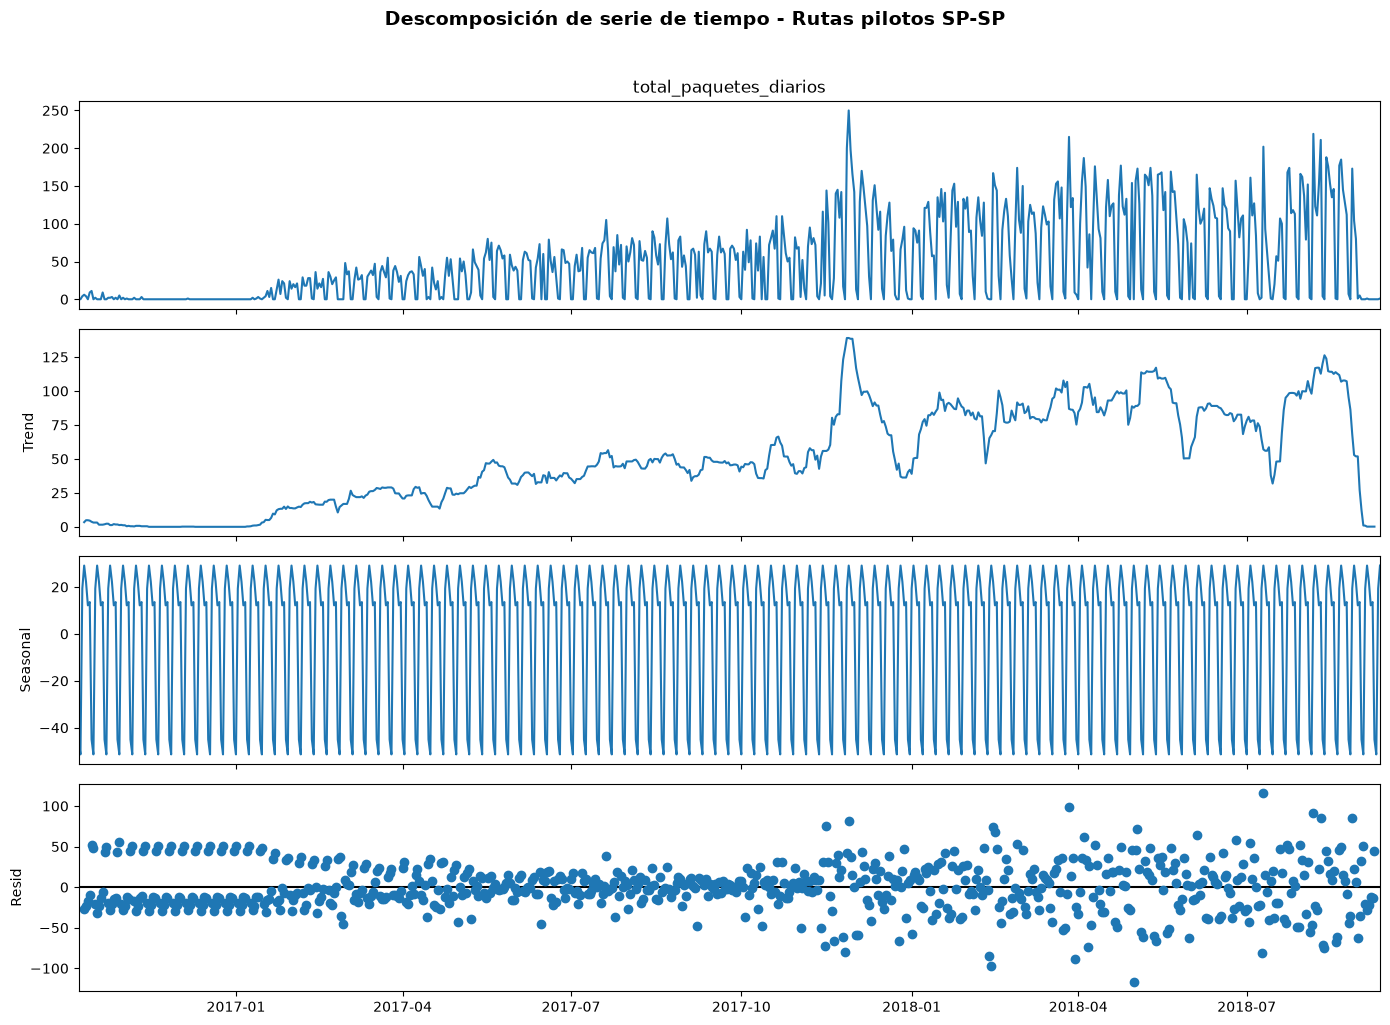

In [5]:
df_piloto_ts =  df_piloto.set_index('fecha')['total_paquetes_diarios'].asfreq('D')
df_piloto_ts = df_piloto_ts.fillna(0)
descomposicion = seasonal_decompose(df_piloto_ts, model='additive', period=7)

fig= descomposicion.plot()
fig.set_size_inches(14,10)

plt.suptitle(f'Descomposición de serie de tiempo - Rutas pilotos {ruta_piloto}', fontsize=14, fontweight='bold', y =1.02 )
plt.tight_layout()
plt.show()

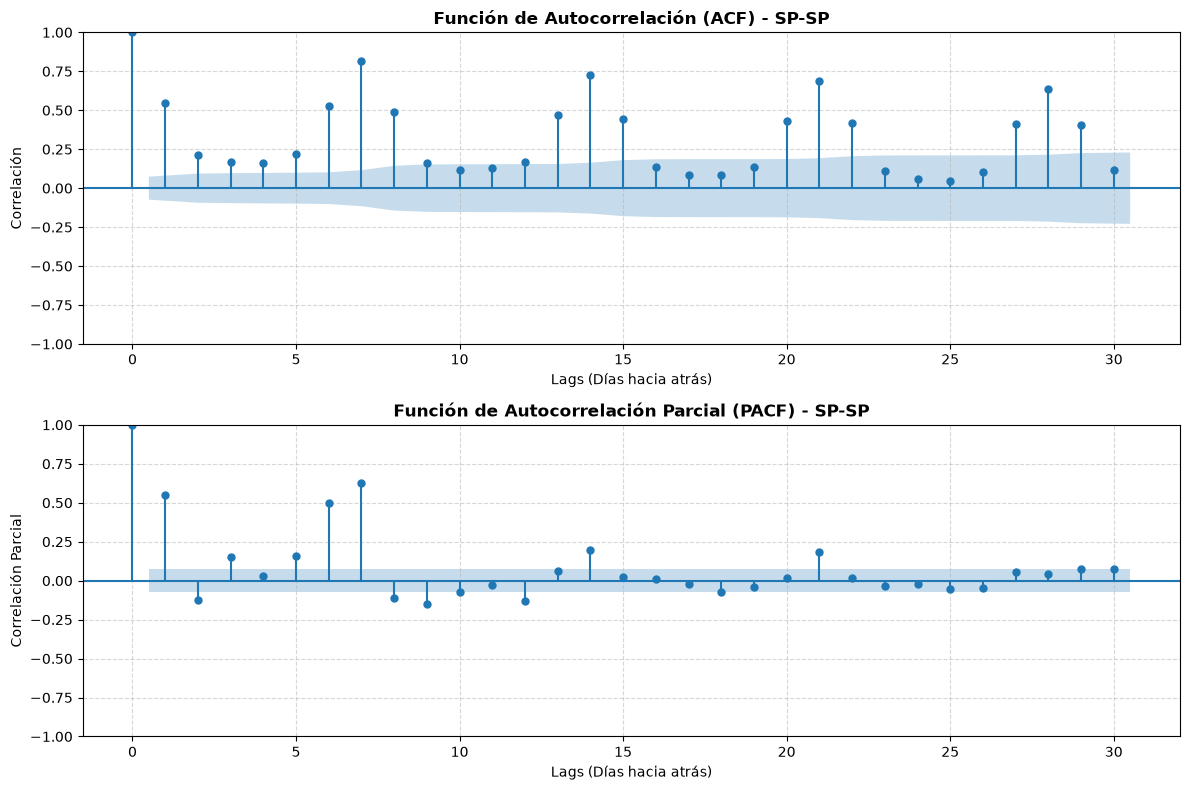

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12,8))

plot_acf(df_piloto_ts, lags=30, ax=axes[0])
axes[0].set_title(f'Función de Autocorrelación (ACF) - {ruta_piloto}', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Lags (Días hacia atrás)')
axes[0].set_ylabel('Correlación')
axes[0].grid(True, linestyle='--', alpha=0.5)


plot_pacf(df_piloto_ts, lags=30, ax=axes[1], method='ywm')
axes[1].set_title(f'Función de Autocorrelación Parcial (PACF) - {ruta_piloto}', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Lags (Días hacia atrás)')
axes[1].set_ylabel('Correlación Parcial')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()